 Copyright © Sorbonne University.

 This source code is licensed under the MIT license found in the LICENSE file
 in the root directory of this source tree.

Students: Lorenzo Messali and Francesco Castelnuovo
GitHub: https://github.com/lorenzomessali3/ASPO-Lab

# Outlook

In this notebook, we learn a forward model and a reward model 
of the MountainCarContinous environment using neural networks.
To evaluate the quality of the learned models, we perform trajectory 
optimization "in imagination" based on the model and determine whether
the obtained trajectories are good when played in the real environment 
instead of the model.

We first do all this naively then work on improving the general framework.

# Installation

In [2]:
import numpy as np
from typing import List, Tuple
import matplotlib
#matplotlib.use("QtAgg")
import matplotlib.pyplot as plt

import gymnasium as gym

from omegaconf import OmegaConf

import torch
import torch.nn as nn
from torch.nn import functional as func

# Hyper-parameters

In [3]:
rng = np.random.default_rng()

params = {
    "nb_episodes": 100,
    "nb_iter": 20,
    "elite_size": 15,
    "pop_size": 200,
    "sequence_len": 1000,
    "sigma": 0.8,
    "noise_multiplier": 0.99999,
    "indiv_repeat": 5,
    "learning_rate": 0.003,
    "train_set_size": 20000,
    }

In [4]:
def make_env(cfg):
    """
    Create the environment
    """
    mdp = gym.make(
        "MountainCarContinuous-v0" # "Pendulum-v1",
    )
    env = mdp.unwrapped  # the .unwrapped removes a warning from gymnasium when accessing an attribute or function
    return mdp, env

cfg=OmegaConf.create(params)
mdp, env = make_env(cfg)
mdp.reset()

(array([-0.53693795,  0.        ], dtype=float32), {})

Visualization of the results

In [5]:
def plot(curve, title):
        plt.plot(curve)

        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()


def plot_evo(scores, title):
        scores = np.array(scores)
        max_curve = scores.max(axis=1)
        mean_curve = scores.mean(axis=1)
        plt.plot(max_curve, color="red")
        plt.plot(mean_curve, color="blue")
        val_min = np.percentile(scores, 25, axis=1)
        val_max = np.percentile(scores, 75, axis=1)
        clipped = np.clip(scores, val_min[:, None], val_max[:, None])
        iqm = np.mean(clipped, axis=1)
        plt.plot(iqm, color="green")
        plt.fill_between(range(len(scores)), val_min, val_max, alpha=0.2, color="green")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

# Trajectory optimization

In this part we generate random action sequences, we evaluate them with a reward function
and we code the Cross-Entropy method to get trajectories of increasing value.

In the code below, write the standard reinforcement learning loop 
where the agent interacts with the environment until the episode 
terminates or is truncated.

In [6]:
def create_random_sequence(env, length):
  actions = [env.action_space.sample().item() for _ in range(length)] # tipo un for 
  return actions

In [7]:
def evaluate_action_sequence_in_env(
    sequence: np.array,
) -> float:
    """
    Perform an episode on the given mdp given a sequence of actions
    :return: the cumulated reward
    """
    total_reward = 0
    _, _ = mdp.reset()
    terminated = False
    truncated = False
    step = 0

    while not terminated and not truncated and step < len(sequence):
        obs, reward, terminated, truncated, info = mdp.step([sequence[step]])
        total_reward += reward 
        step += 1

    return total_reward

In [8]:
# Prova per capire che con azioni casuali la macchina oscilla nella valle 
seq = create_random_sequence(env, cfg.sequence_len)
print(evaluate_action_sequence_in_env(seq))

-33.9022773953108


In [9]:
def evaluate_in_env(pop):
    scores = []
    for i in range(len(pop)):
        indiv_scores = []
        for _ in range(cfg.indiv_repeat):
            indiv_scores.append(evaluate_action_sequence_in_env(pop[i]))
            score = np.mean(indiv_scores)
        scores.append(score)
    return scores

## Real reward function of MountainCarContinuous

Find its definition on internet and fill the code

In [10]:
def reward_function(state, action):
    """
    Reward function for MountainCarContinuous.

    Parameters
    ----------
    position : float
        Car position after the transition.
    action : float or np.ndarray
        Action applied (typically in [-1, 1]).

    Returns
    -------
    float
        Reward for the transition.
    """
    action = np.array(action).item() # cosi sono siucuro che funziona anche con array
    position = state[0]
    reward = -0.1*action**2

    if position >= 0.45:
        reward += 100
    

    return reward

In [11]:
# Test in due situazioni, la prima sono nella valle e ho azione negativa, la seconda sono già sulla bandierina e ricevo 100- il costo dell'azione 
print(reward_function([0.0, 0.0], 0.5))    # in valle, azione 0.5
print(reward_function([0.5, 0.0], 0.5))    # oltre la bandierina, azione 0.5

-0.025
99.975


The full code for the cross-entropy method is given. Anyways, try to understand it, it is rather easy.

In [12]:
class CovMatrix:

    def __init__(self, centroid, sigma=0.1,
                 noise_multiplier=0.9,
                 diag_cov=True):

        self.diag_cov = diag_cov
        self.noise_multiplier = noise_multiplier
        n = len(centroid)
        self.noise = np.diag(np.ones(n) * sigma)

        self.cov = np.diag(np.ones(n) * np.var(centroid)) + self.noise

    def update_noise(self):
        self.noise = [
            x * self.noise_multiplier
            for x in self.noise
        ]

    def generate_pop(self, centroid, pop_size):
        return rng.multivariate_normal(centroid, self.cov, pop_size)

    def update_covariance(self, elite):
        self.cov = np.cov(np.transpose(elite)) + self.noise
        self.cov += 1e-6 * np.eye(self.cov.shape[0])

In [13]:
class CEM:

    def __init__(self, mu_init, elites_nb, **kwargs):

        self.centroid = mu_init
        self.elites_nb = elites_nb
        self.cov_matrix = CovMatrix(
            mu_init,
            **kwargs
        )

    def ask(self, pop_size):
        return self.cov_matrix.generate_pop(
            self.centroid,
            pop_size
        )

    def tell(self, params, fitness):

        # indices of best individuals
        elite_indices = sorted(
            range(len(fitness)),
            key=lambda i: fitness[i]
        )[-self.elites_nb:]

        elite = [
            params[i]
            for i in elite_indices
        ]

        # update centroid
        n = len(elite[0])

        self.centroid = [
            sum(w[j] for w in elite) / len(elite)
            for j in range(n)
        ]

        self.cov_matrix.update_noise()
        self.cov_matrix.update_covariance(elite)

## Performance of the CEM in the real environment

Write the main loop to try the above code

In [ ]:
def cem_in_env():

    seq = create_random_sequence(env, cfg.sequence_len)

    cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
    punteggi = []

    for i in range(cfg.nb_iter):
        pop = cem.ask(cfg.pop_size)
        marks = evaluate_in_env(pop)   # Ottengo 200 voti 
        cem.tell(pop, marks)
        punteggi.append(marks)

    plot_evo(punteggi, title= "punteggi")



**CEM in the real environment.**

The best sequence (red) can reach the flag already in the first iterations, because some random sequences of the population happen to be "energetic" enough. The mean and the IQM typically drop during the first iterations and then rise.
The initial drop comes from the covariance update: the noise is added to the covariance of the elites at every iteration, and with `noise_multiplier = 0.99999` it is almost never reduced. The population spreads, actions leave [−1, 1] and the action penalty (computed on the unclipped action) grows. Afterwards, elite selection takes over and the population improves.
The CEM rarely reaches the "solved" level (≈ +90) because it optimizes an open-loop sequence of 1000 actions: a very high-dimensional search space, and a sequence that cannot adapt to the random initial position.

# Learning forward dynamics and reward models with neural networks

The function below builds a multi-layer perceptron where the size of each
layer is given in the `size` list. We also specify the activation function of
neurons at each layer and optionally a different activation function for the
final layer.

All the code for representing and training neural networks is provided, but read it to understand it.
You need to fill the code of ```evaluate()``` function. 
It evaluates all individuals from the population by taking the average over cfg.indiv_repeat runs.
The parameter ```learned_reward``` tells whether we want to evaluate with the real reward function 
or the learned model of this function.

In [ ]:
def build_mlp(sizes, activation, output_activation=nn.Identity()):
    """Helper function to build a multi-layer perceptron (function from $\mathbb R^n$ to $\mathbb R^p$)
    
    Args:
        sizes (List[int]): the number of neurons at each layer
        activation (nn.Module): a PyTorch activation function (after each layer but the last)
        output_activation (nn.Module): a PyTorch activation function for the last layer
    """
    layers = []
    for j in range(len(sizes) - 1):
        act = activation if j < len(sizes) - 2 else output_activation
        layers += [nn.Linear(sizes[j], sizes[j + 1]), act]
    return nn.Sequential(*layers)

In [ ]:
class NeuralNetwork():
    def __init__(self, sizes, activation, output_activation):
        self.model = build_mlp(sizes, activation, output_activation)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=cfg.learning_rate)

    def train(self, input, output):
        x = self.forward(input).squeeze()
        loss = func.mse_loss(torch.Tensor(np.array(output)),x)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return loss.detach().numpy()

    def forward(self, input):
        x = torch.Tensor(np.array(input))
        return self.model.forward(x)

In [ ]:
class Model():
    def __init__(self, sizes, activation, output_activation):
        self.forward_model = NeuralNetwork(sizes + [2], activation, output_activation)
        self.reward_model = NeuralNetwork(sizes + [1], activation, output_activation)

    def train_models(self):
        forward_losses = []
        reward_losses = []
        for i in range(cfg.train_set_size):
            action_sequence = create_random_sequence(env, cfg.sequence_len)
            states, actions, rewards, delta_states = collect_transition_and_reward_in_env(action_sequence)
            input = [np.concatenate((x, [y])) for x, y in zip(states, actions)]
            forward_loss = self.forward_model.train(input, delta_states)
            reward_loss = self.reward_model.train(input, rewards)
            forward_losses.append(forward_loss)
            reward_losses.append(reward_loss)
        # plot(forward_losses, "forward loss")
        # plot(reward_losses, "reward loss")

       
    def evaluate_one_action_sequence(self,
        sequence: np.array, learned_reward
    ) -> int:
        """
        Perform an episode in imagination given a sequence of actions
        :return: the cumulated reward
        """
        total_reward = 0
        state, _ = mdp.reset()
        steps = 0

        while steps < len(sequence) and state[0] < 0.45:
            action = sequence[steps]
            input = np.concatenate((state, [action]))

            delta = self.forward_model.forward(input).detach().numpy()
            next_state = state + delta

            if learned_reward:
                reward = self.reward_model.forward(input).item()
            else:
                reward = reward_function(next_state, action)

            total_reward += reward
            state = next_state
            steps += 1
       
        return total_reward

    def evaluate(self, pop, learned_reward=True):
        scores = []
        for i in range(len(pop)):
            indiv_scores = []
            for _ in range(cfg.indiv_repeat):
                indiv_scores.append(self.evaluate_one_action_sequence(pop[i], learned_reward))
            scores.append(np.mean(indiv_scores))

        return scores

In [ ]:
def collect_transition_and_reward_in_env(
    sequence: np.array,
) -> Tuple[List, List, List, List]:
    """
    Perform an episode on the given mdp given a sequence of actions
    :return: the cumulated reward
    """
    states = []
    actions = []
    rewards = []
    delta_states = []
    state, _ = mdp.reset()
    terminated = False
    truncated = False
    steps = 0

    while not terminated and not truncated and steps < len(sequence):
        action = sequence[steps]
        next_state, reward, terminated, truncated, info = mdp.step([action])

        states.append(state)
        actions.append(action)
        rewards.append(reward)
        delta_states.append(next_state - state)

        state = next_state
        steps += 1

    return states, actions, rewards, delta_states

## Performance of the CEM trained with learned models

In the code below, we first learn a forward model and a reward model, then we apply
the CEM "in imagination" using the learned models, and we evaluate the performance
of the best trajectory found in the real environment.

In [ ]:
def cem_in_full_model():
    
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())

    model.train_models()

    seq = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
    all_scores = []

    for i in range(cfg.nb_iter):
        pop = cem.ask(cfg.pop_size)
        marks = model.evaluate(pop, learned_reward=True)
        cem.tell(pop, marks)
        all_scores.append(marks)
        print(i, max(marks))

    plot_evo(all_scores, "CEM nel full model (reward imparata)")

    real_score = evaluate_action_sequence_in_env(cem.centroid)
    print("Punteggio reale del centroide:", real_score)
   

In [ ]:
def cem_in_forward_model():
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())

    # Training
    model.train_models()

    # CEM
    seq = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
    all_scores = []

    for i in range(cfg.nb_iter):
        pop = cem.ask(cfg.pop_size)
        marks = model.evaluate(pop, learned_reward=False)
        cem.tell(pop, marks)
        all_scores.append(marks)
        print(i, max(marks))

    plot_evo(all_scores, "CEM nel forward model (reward vera)")

    real_score = evaluate_action_sequence_in_env(cem.centroid)
    print("Punteggio reale del centroide:", real_score)



In [ ]:
cfg.train_set_size = 200
cfg.nb_iter = 3
cfg.pop_size = 20
cem_in_forward_model()

## The line to run what you want to try

In [ ]:
cem_in_forward_model()

# Improvements

If you just followed instructions so far, you should have found that the naive approach
does not work.

There are several reasons why this fails:
- The models are trained from random sequences of actions. In MountainCarContinuous, 
with such random actions the car will most likely stay in the valley between hills: 
it does not learn much of the dynamics outside the valley. Training models with better 
sequences of actions (for instance those provided by the CEM) would improve that.
- Same point about the reward function: getting on the top of the hill is necessary 
to get the large positive reward. This (almost) never happens with random sequences of actions, 
hence the neural network cannot learn a proper reward model.
- The neural network is trained from data arriving sequentially. 
Such data is highly correlated. Using a dataloader would facilitate shuffling the data 
to prevent these correlations.
- Playing a long trajectory in imagination suffers from a coumpounding error issue: 
even if the models are making very small mistakes, these errors accumulate and 
the imagined trajectory ends up visiting states that are very different from 
the one it would visit in the real environment.

Now your goal is to turn the above code into something that works. We suggest the following changes:
- replace the model of the reward function by the true reward function and see if this works
- use a dataloader, shuffle the data and consider a validation loss when training the models
- create a dataset of successful trajectories using the CEM rather than using random trajectories
- learn a more sophisticated model of the reward function combining the goal-related reward (0, +100) 
and the action penalty reward.
- better tune all hyper-parameters, ask suggestions to your favorite generative AI.

Try as much as the above elements as you can and present your findings 
in a separate pdf document with figures.

Imagination - reward imparata - iter 0 - miglior voto immaginato: -0.8065838783979415
Imagination - reward imparata - iter 1 - miglior voto immaginato: -0.7330856561660767
Imagination - reward imparata - iter 2 - miglior voto immaginato: -0.5414969861507416


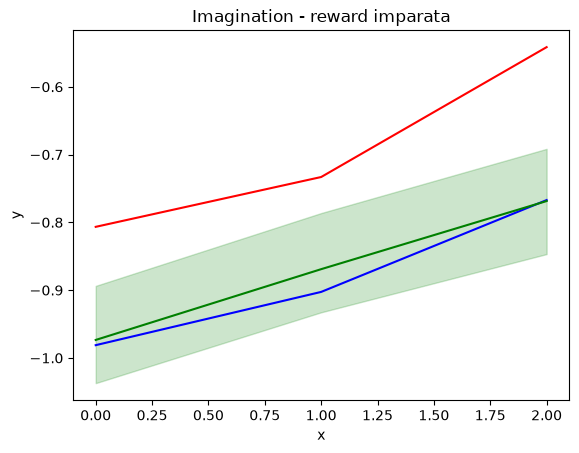

Imagination - reward vera - iter 0 - miglior voto immaginato: 97.25783578537639
Imagination - reward vera - iter 1 - miglior voto immaginato: 96.13065617851946
Imagination - reward vera - iter 2 - miglior voto immaginato: 96.0068597777216


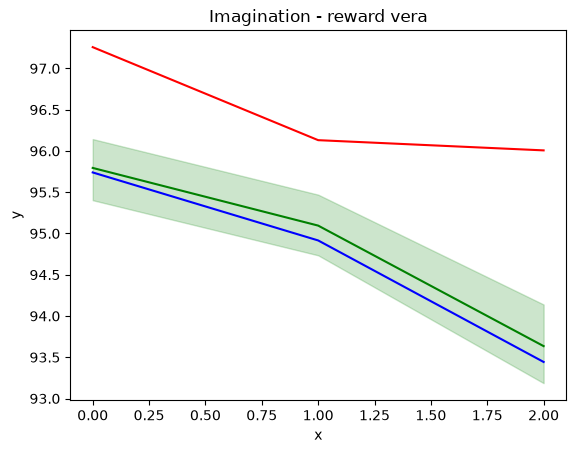

Punteggio reale - reward imparata: -65.6790994365759
Punteggio reale - reward vera:     -73.76068240803887


In [24]:

# =====================================================================
# IMPROVEMENT 1: sostituire il reward model con la reward function vera
# =====================================================================

cfg.train_set_size = 200
cfg.nb_iter = 3
cfg.pop_size = 20


def cem_in_imagination(model, learned_reward, title):
    """CEM in immaginazione con un modello GIA' allenato.
    Restituisce il punteggio reale del centroide finale."""
    seq = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
    all_scores = []

    for i in range(cfg.nb_iter):
        pop = cem.ask(cfg.pop_size)
        marks = model.evaluate(pop, learned_reward=learned_reward)
        cem.tell(pop, marks)
        all_scores.append(marks)
        print(title, "- iter", i, "- miglior voto immaginato:", max(marks))

    plot_evo(all_scores, title)
    real_score = evaluate_action_sequence_in_env(cem.centroid)
    return real_score


# 1. Alleno UN SOLO modello (forward + reward) sui dati casuali
model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
model.train_models()

# 2. Stesso modello, due versioni dell'immaginazione
score_learned = cem_in_imagination(model, learned_reward=True,  title="Imagination - reward imparata")
score_true    = cem_in_imagination(model, learned_reward=False, title="Imagination - reward vera")

# 3. Confronto nell'ambiente reale
print("Punteggio reale - reward imparata:", score_learned)
print("Punteggio reale - reward vera:    ", score_true)

**Improvement 1: true reward function instead of the learned reward model.**
true reward instead of the learned reward model.
We train one model (forward + reward) on random episodes and run the CEM in imagination twice, changing only the reward.

Learned reward: imagined scores stay small and negative. The +100 is almost absent from random data, so the CEM only learns to save energy.
True reward: imagined scores can be very high for almost every sequence. Small one-step errors of the forward model accumulate along the trajectory (compounding error), and the imagined car drifts to the top.
Real scores: in both cases the real car does not reach the flag.

Conclusion: the true reward fixes the reward model, not the forward model. The CEM exploits the model’s errors (model exploitation), so the main bottleneck is the forward model and its training data.

Numero di transizioni: 199800


/var/folders/87/6r_6ppqx32nb_w8t051wjgtr0000gn/T/ipykernel_37040/804531354.py:15: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = torch.Tensor(np.array(input))
/var/folders/87/6r_6ppqx32nb_w8t051wjgtr0000gn/T/ipykernel_37040/804531354.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  loss = func.mse_loss(torch.Tensor(np.array(output)),x)


0 forward: 0.00041209577 1.1413349e-05 reward: 0.00018562496 5.8409487e-06
1 forward: 1.9202191e-06 4.97951e-07 reward: 5.7468633e-06 5.342489e-06
2 forward: 4.288488e-07 3.6351548e-07 reward: 4.31704e-06 2.4666122e-06
3 forward: 3.4694247e-07 3.051399e-07 reward: 3.9938814e-06 4.6975456e-06
4 forward: 2.9604178e-07 2.6171293e-07 reward: 3.3396861e-06 3.2785672e-06
5 forward: 2.548666e-07 2.1728081e-07 reward: 3.1290115e-06 1.5697551e-06
6 forward: 2.1902596e-07 1.8563489e-07 reward: 2.7914114e-06 1.4305584e-06
7 forward: 1.9124501e-07 1.6074513e-07 reward: 2.569141e-06 1.2977267e-06
8 forward: 1.8978558e-07 1.6431831e-07 reward: 2.63821e-06 1.4669648e-06
9 forward: 3.8996592e-07 1.5353137e-07 reward: 2.40782e-06 1.1704502e-06


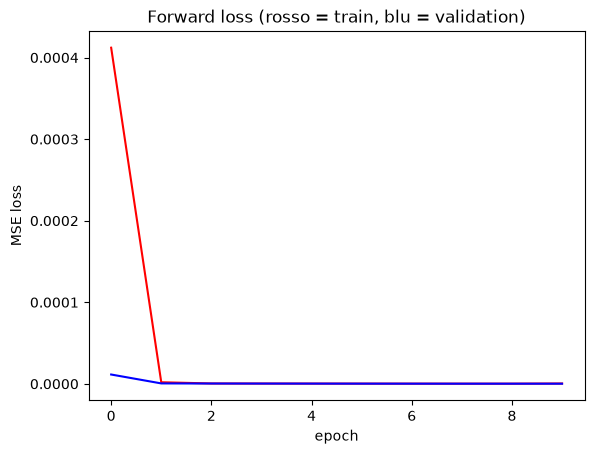

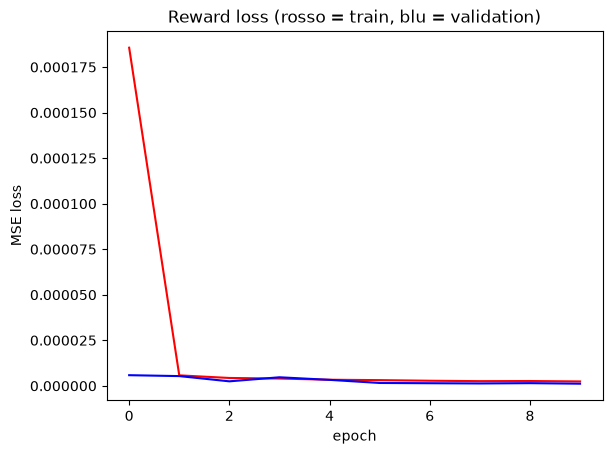

Imagination (dataloader) - reward imparata - iter 0 - miglior voto immaginato: -55.849805584549905
Imagination (dataloader) - reward imparata - iter 1 - miglior voto immaginato: -34.44206756949425
Imagination (dataloader) - reward imparata - iter 2 - miglior voto immaginato: -34.2944182664156


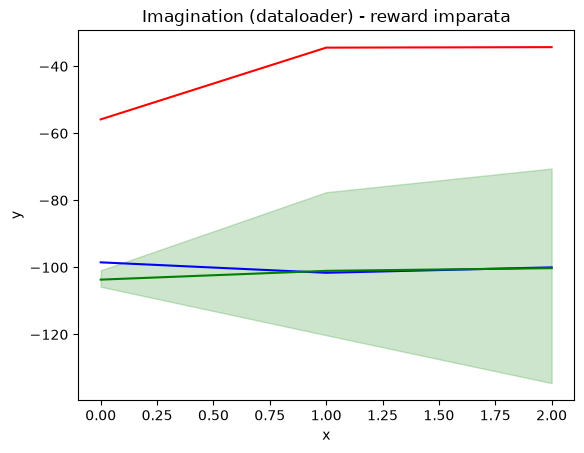

Imagination (dataloader) - reward vera - iter 0 - miglior voto immaginato: -30.265543906792846
Imagination (dataloader) - reward vera - iter 1 - miglior voto immaginato: 60.778407236843236
Imagination (dataloader) - reward vera - iter 2 - miglior voto immaginato: 26.75065488666081


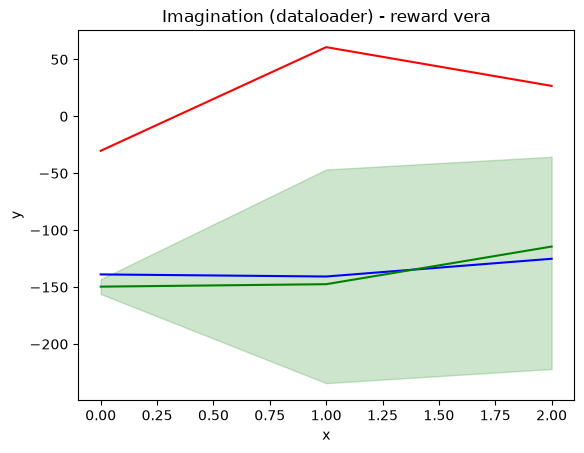

Punteggio reale - reward imparata: -60.38252068813499
Punteggio reale - reward vera:     -71.86186821570742


In [25]:
# =====================================================================
# IMPROVEMENT 2: dataloader + shuffle + validation loss
# =====================================================================
from torch.utils.data import TensorDataset, DataLoader

# Parametri piccoli per il test
cfg.train_set_size = 200   # numero di episodi raccolti
cfg.nb_iter = 3
cfg.pop_size = 20
nb_epochs = 10             # quante volte si ripassa tutto il train set
batch_size = 256           # transizioni per ogni passo di Adam


def collect_dataset(nb_episodes):
    """Raccoglie tutte le transizioni di nb_episodes episodi casuali."""
    inputs = []
    deltas = []
    rewards_all = []
    for i in range(nb_episodes):
        action_sequence = create_random_sequence(env, cfg.sequence_len)
        states, actions, rewards, delta_states = collect_transition_and_reward_in_env(action_sequence)
        for x, y, r, d in zip(states, actions, rewards, delta_states):
            inputs.append(np.concatenate((x, [y])))
            deltas.append(d)
            rewards_all.append(r)
    return np.array(inputs), np.array(deltas), np.array(rewards_all)


def validation_loss(network, input, output):
    """MSE della rete su dati che non usa per allenarsi."""
    x = network.forward(input).squeeze()
    loss = func.mse_loss(torch.Tensor(output), x)
    return loss.detach().numpy()


def train_models_dataloader(model, inputs, deltas, rewards):
    # divisione 80% train / 20% validation
    indices = rng.permutation(len(inputs))
    n_train = int(0.8 * len(inputs))
    train_idx = indices[:n_train]
    val_idx = indices[n_train:]

    # il DataLoader mescola il train set e lo serve a mini-batch
    train_set = TensorDataset(torch.Tensor(inputs[train_idx]),
                              torch.Tensor(deltas[train_idx]),
                              torch.Tensor(rewards[train_idx]))
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)

    forward_train, forward_val = [], []
    reward_train, reward_val = [], []
    for epoch in range(nb_epochs):
        forward_losses = []
        reward_losses = []
        for x, d, r in train_loader:
            forward_losses.append(model.forward_model.train(x, d))
            reward_losses.append(model.reward_model.train(x, r))
        forward_train.append(np.mean(forward_losses))
        reward_train.append(np.mean(reward_losses))
        forward_val.append(validation_loss(model.forward_model, inputs[val_idx], deltas[val_idx]))
        reward_val.append(validation_loss(model.reward_model, inputs[val_idx], rewards[val_idx]))
        print(epoch, "forward:", forward_train[-1], forward_val[-1], "reward:", reward_train[-1], reward_val[-1])
    return forward_train, forward_val, reward_train, reward_val


def plot_train_val(train, val, title):
    plt.plot(train, color="red")
    plt.plot(val, color="blue")
    plt.xlabel("epoch")
    plt.ylabel("MSE loss")
    plt.title(title + " (rosso = train, blu = validation)")
    plt.show()


# 1. raccolta del dataset
inputs, deltas, rewards = collect_dataset(cfg.train_set_size)
print("Numero di transizioni:", len(inputs))

# 2. allenamento con dataloader
model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
forward_train, forward_val, reward_train, reward_val = train_models_dataloader(model, inputs, deltas, rewards)
plot_train_val(forward_train, forward_val, "Forward loss")
plot_train_val(reward_train, reward_val, "Reward loss")

# 3. CEM in immaginazione (stesso confronto dell'Improvement 1)
score_learned = cem_in_imagination(model, learned_reward=True,  title="Imagination (dataloader) - reward imparata")
score_true    = cem_in_imagination(model, learned_reward=False, title="Imagination (dataloader) - reward vera")
print("Punteggio reale - reward imparata:", score_learned)
print("Punteggio reale - reward vera:    ", score_true)

**Improvement 2: dataloader, shuffle and validation loss.**


Instead of one gradient step per episode on correlated transitions, we build a single dataset (80/20 train/validation split) and train for several epochs on shuffled mini-batches.

Forward loss: drops within the first epoch, and train and validation curves overlap, so there is no overfitting. Since all data comes from the valley, the model is presumably reliable only there.
Reward loss: the train loss stays high and flat, while the validation loss is close to zero. The rare +100 transitions dominate the MSE, and the network cannot learn such a rare event.
Imagination: scores become more varied and realistic, since the forward model is much better trained.
Real scores: the car still does not reach the flag.

Conclusion: better training improves the model, but it cannot learn what it has never seen. The problem is the data, which comes almost only from the valley.

CEM reale - iter 0 - miglior voto: -38.78624084765865
CEM reale - iter 1 - miglior voto: -0.6617645827340481
CEM reale - iter 2 - miglior voto: 27.879915156795512
CEM reale - iter 3 - miglior voto: 19.759886170846485
CEM reale - iter 4 - miglior voto: -0.2246419680458729


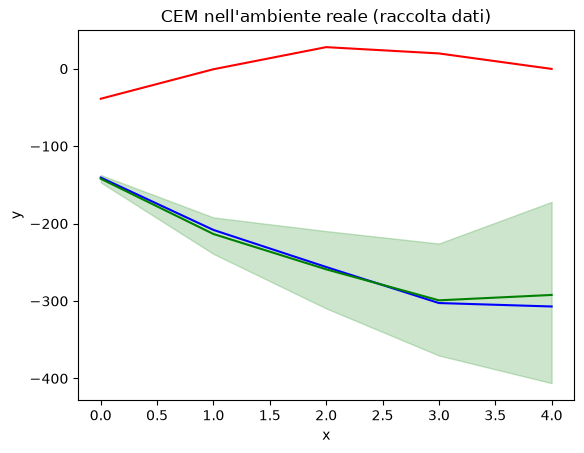

Sequenze di successo: 3 su 500
Numero di transizioni: 276732
Transizioni con +100: 191


/var/folders/87/6r_6ppqx32nb_w8t051wjgtr0000gn/T/ipykernel_37040/804531354.py:15: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = torch.Tensor(np.array(input))
/var/folders/87/6r_6ppqx32nb_w8t051wjgtr0000gn/T/ipykernel_37040/804531354.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  loss = func.mse_loss(torch.Tensor(np.array(output)),x)


0 forward: 0.000551572 2.0893874e-06 reward: 6.96582 5.007552
1 forward: 1.536153e-06 1.2076273e-06 reward: 6.0597434 4.333263
2 forward: 9.156637e-07 8.025058e-07 reward: 5.3692346 4.993995
3 forward: 6.7367955e-07 7.745401e-07 reward: 4.794185 3.5868495
4 forward: 5.825396e-07 5.6386097e-07 reward: 4.3597198 2.841706
5 forward: 5.4613497e-07 5.843905e-07 reward: 3.9913242 2.7339933
6 forward: 5.5221165e-07 5.80425e-07 reward: 3.436401 2.299571
7 forward: 5.8747605e-07 5.169058e-07 reward: 3.196137 3.3714902
8 forward: 6.4358255e-07 9.201481e-07 reward: 2.891216 1.7896074
9 forward: 6.6857683e-07 2.3863777e-06 reward: 3.0972216 2.1665957


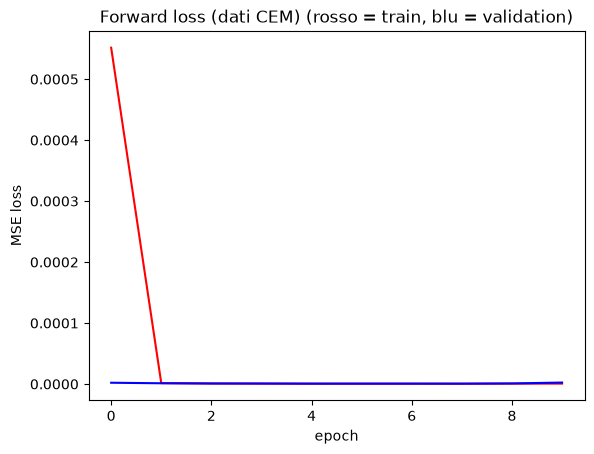

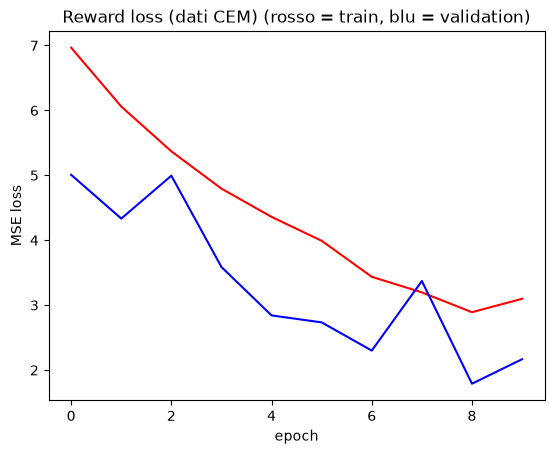

Imagination (dati CEM) - reward imparata - iter 0 - miglior voto immaginato: -1.9143434524536134
Imagination (dati CEM) - reward imparata - iter 1 - miglior voto immaginato: 8.007867765426635
Imagination (dati CEM) - reward imparata - iter 2 - miglior voto immaginato: -2.8272639751434325
Imagination (dati CEM) - reward imparata - iter 3 - miglior voto immaginato: -12.312149238586425


KeyboardInterrupt: 

In [26]:
# =====================================================================
# IMPROVEMENT 3: dataset con traiettorie di successo trovate dal CEM
# =====================================================================

# Parametri (medi: con 3 iterazioni e 20 sequenze il CEM non trova quasi mai la bandierina)
cfg.train_set_size = 200   # episodi casuali + episodi CEM
cfg.nb_iter = 5
cfg.pop_size = 100
nb_epochs = 10
batch_size = 256


# 1. CEM nell'ambiente reale: raccolgo le sequenze e i loro voti
seq = create_random_sequence(env, cfg.sequence_len)
cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
all_scores = []
all_pops = []
all_marks = []
for i in range(cfg.nb_iter):
    pop = cem.ask(cfg.pop_size)
    marks = evaluate_in_env(pop)
    cem.tell(pop, marks)
    all_scores.append(marks)
    for s, m in zip(pop, marks):
        all_pops.append(s)
        all_marks.append(m)
    print("CEM reale - iter", i, "- miglior voto:", max(marks))
plot_evo(all_scores, "CEM nell'ambiente reale (raccolta dati)")

# tengo solo le sequenze che arrivano in cima (voto > 0)
good_sequences = [s for s, m in zip(all_pops, all_marks) if m > 0]
print("Sequenze di successo:", len(good_sequences), "su", len(all_pops))
if len(good_sequences) == 0:
    good_sequences = all_pops   # sicurezza: se nessuna arriva in cima uso tutte quelle del CEM


# 2. Dataset misto: metà episodi casuali, metà episodi con sequenze di successo
def collect_dataset_from_sequences(sequences):
    inputs = []
    deltas = []
    rewards_all = []
    for action_sequence in sequences:
        states, actions, rewards, delta_states = collect_transition_and_reward_in_env(action_sequence)
        for x, y, r, d in zip(states, actions, rewards, delta_states):
            inputs.append(np.concatenate((x, [y])))
            deltas.append(d)
            rewards_all.append(r)
    return np.array(inputs), np.array(deltas), np.array(rewards_all)

random_sequences = [create_random_sequence(env, cfg.sequence_len) for i in range(cfg.train_set_size)]
cem_sequences = [good_sequences[rng.integers(len(good_sequences))] for i in range(cfg.train_set_size)]
inputs, deltas, rewards = collect_dataset_from_sequences(random_sequences + cem_sequences)
print("Numero di transizioni:", len(inputs))
print("Transizioni con +100:", (rewards > 50).sum())


# 3. Allenamento con dataloader (come Improvement 2)
model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
forward_train, forward_val, reward_train, reward_val = train_models_dataloader(model, inputs, deltas, rewards)
plot_train_val(forward_train, forward_val, "Forward loss (dati CEM)")
plot_train_val(reward_train, reward_val, "Reward loss (dati CEM)")


# 4. CEM in immaginazione + verifica reale (stesso esperimento di prima)
score_learned = cem_in_imagination(model, learned_reward=True,  title="Imagination (dati CEM) - reward imparata")
score_true    = cem_in_imagination(model, learned_reward=False, title="Imagination (dati CEM) - reward vera")
print("Punteggio reale - reward imparata:", score_learned)
print("Punteggio reale - reward vera:    ", score_true)

**Improvement 3: training data collected with the CEM.**


The dataset mixes random episodes and episodes played with CEM sequences from the real environment. These sequences are more “energetic”, so the car explores the hills and reaches the flag more often.

Forward loss: same behaviour as before, but now on data that also covers the hills.
Reward loss: higher, because there are more +100 transitions, but now it decreases: the network starts to learn the goal reward.
Learned reward: for the first time, imagined scores can be positive, and the CEM actively looks for the goal.
True reward: scores are more realistic, but the reward is sparse, so the CEM gets no signal until an imagined trajectory reaches the top.
Real scores: depending on the run, the learned-reward version can reach the flag.

Conclusion: changing the data is the key improvement, since the model becomes a more reliable simulator. With few successful examples, however, results vary from run to run.

In [ ]:
# =====================================================================
# IMPROVEMENT 4: reward model a due parti (bandierina + penalità)
# =====================================================================

oversampling = 500   # quante volte ripeto ogni transizione con bandierina nel train

# 1. Etichette: 1 se la transizione prende il +100, 0 altrimenti
goal_labels = (rewards > 50).astype(np.float32)
print("Transizioni con bandierina:", int(goal_labels.sum()), "su", len(goal_labels))

# 2. Divisione train / validation (come Improvement 2)
indices = rng.permutation(len(inputs))
n_train = int(0.8 * len(inputs))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

# 3. Oversampling: ripeto le transizioni con bandierina SOLO nel train
pos_idx = train_idx[goal_labels[train_idx] == 1]
train_idx = np.concatenate((train_idx, np.repeat(pos_idx, oversampling)))
print("Bandierine nel train:", len(pos_idx), "- nella validation:", int(goal_labels[val_idx].sum()))

# 4. Classificatore = NeuralNetwork del prof con Sigmoid in uscita (probabilità tra 0 e 1)
goal_net = NeuralNetwork([3, 10, 10, 10, 1], nn.Tanh(), nn.Sigmoid())
train_set = TensorDataset(torch.Tensor(inputs[train_idx]), torch.Tensor(goal_labels[train_idx]))
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)

goal_train, goal_val = [], []
for epoch in range(nb_epochs):
    losses = []
    for x, y in train_loader:
        losses.append(goal_net.train(x, y))
    goal_train.append(np.mean(losses))
    goal_val.append(validation_loss(goal_net, inputs[val_idx], goal_labels[val_idx]))
    print(epoch, "train:", goal_train[-1], "val:", goal_val[-1])
plot_train_val(goal_train, goal_val, "Goal network loss")


# 5. Valutazione in immaginazione con la reward a due parti
#    (copia di evaluate_one_action_sequence: cambia solo la riga della reward)
def evaluate_one_sequence_two_parts(sequence):
    total_reward = 0
    state, _ = mdp.reset()
    steps = 0
    while steps < len(sequence) and state[0] < 0.45:
        action = sequence[steps]
        input = np.concatenate((state, [action]))
        delta = model.forward_model.forward(input).detach().numpy()   # forward model dell'Improvement 3
        next_state = state + delta
        p_goal = goal_net.forward(input).item()                       # probabilità di bandierina
        reward = 100 * p_goal - 0.1 * action**2                        # parte appresa + parte esatta
        total_reward += reward
        state = next_state
        steps += 1
    return total_reward

def evaluate_two_parts(pop):
    # copia di evaluate_in_env
    scores = []
    for i in range(len(pop)):
        indiv_scores = []
        for _ in range(cfg.indiv_repeat):
            indiv_scores.append(evaluate_one_sequence_two_parts(pop[i]))
        scores.append(np.mean(indiv_scores))
    return scores


# 6. CEM in immaginazione (stesso ciclo di cem_in_env) + verifica reale
seq = create_random_sequence(env, cfg.sequence_len)
cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
all_scores = []
for i in range(cfg.nb_iter):
    pop = cem.ask(cfg.pop_size)
    marks = evaluate_two_parts(pop)
    cem.tell(pop, marks)
    all_scores.append(marks)
    print("Imagination due parti - iter", i, "- miglior voto immaginato:", max(marks))
plot_evo(all_scores, "Imagination - reward a due parti")

score_two_parts = evaluate_action_sequence_in_env(cem.centroid)
print("Punteggio reale - reward a due parti:", score_two_parts)
print("(Improvement 3 - reward imparata: 63.3 / reward vera: -131.3)")

**Improvement 4: two-part reward model.**

The reward is split in two: the action penalty −0.1·a² is computed exactly, and a classifier (Sigmoid output) learns the probability of reaching the flag. Predicted reward = 100 · P(goal) − 0.1·a². Positive examples are oversampled in the training set only.

Classifier loss: low and decreasing, with train and validation close.
Imagination: imagined scores can exceed 100, which is impossible in reality. Near the top, several consecutive steps get a high P(goal), so the “partial” +100 rewards add up, while the real +100 is given only once.
Real scores: much lower than the imagined ones.

Conclusion: an accurate classifier is not enough: it must be used consistently with the real reward, otherwise the CEM exploits the error. A possible fix is to end the imagined episode when P(goal) > 0.5, so the goal reward is counted only once.

In [ ]:
# =====================================================================
# VERSIONE FINALE: tutti gli improvements insieme
#   Impr. 1: reward vera vs reward imparata
#   Impr. 2: dataloader + shuffle + validation loss
#   Impr. 3: dataset con sequenze del CEM (oltre a quelle casuali)
#   Impr. 4: reward a due parti (classificatore bandierina + penalità esatta)
#   Impr. 5: iperparametri scelti
# =====================================================================
from torch.utils.data import TensorDataset, DataLoader

# ---------------- Iperparametri (Improvement 5) ----------------
cfg.sigma = 0.8
cfg.noise_multiplier = 0.9       # il rumore del CEM ora decresce davvero
cfg.elite_size = 15
cfg.pop_size = 100
cfg.nb_iter = 10
cfg.indiv_repeat = 5
nb_random_episodes = 300
nb_cem_episodes = 300
nb_epochs = 20
batch_size = 256
hidden = [3, 32, 32]             # input (p, v, a) + 2 strati nascosti da 32
oversampling = 500               # ripetizioni delle transizioni con bandierina (solo train)



# ---------------- Funzioni di supporto ----------------
def run_cem(evaluate_fn, title):
    """Ciclo del CEM (come cem_in_env). Restituisce il centroide e tutte le sequenze provate."""
    seq = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(seq, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)
    all_scores, all_pops, all_marks = [], [], []
    for i in range(cfg.nb_iter):
        pop = cem.ask(cfg.pop_size)
        marks = evaluate_fn(pop)
        cem.tell(pop, marks)
        all_scores.append(marks)
        for s, m in zip(pop, marks):
            all_pops.append(s)
            all_marks.append(m)
        print(title, "- iter", i, "- miglior voto:", max(marks))
    plot_evo(all_scores, title)
    return cem.centroid, all_pops, all_marks


def collect_dataset_from_sequences(sequences):
    inputs, deltas, rewards_all = [], [], []
    for action_sequence in sequences:
        states, actions, rewards, delta_states = collect_transition_and_reward_in_env(action_sequence)
        for x, y, r, d in zip(states, actions, rewards, delta_states):
            inputs.append(np.concatenate((x, [y])))
            deltas.append(d)
            rewards_all.append(r)
    return np.array(inputs), np.array(deltas), np.array(rewards_all)


def validation_loss(network, input, output):
    x = network.forward(input).squeeze()
    loss = func.mse_loss(torch.Tensor(output), x)
    return loss.detach().numpy()


def plot_train_val(train, val, title):
    plt.plot(train, color="red")
    plt.plot(val, color="blue")
    plt.xlabel("epoch")
    plt.ylabel("MSE loss")
    plt.title(title + " (rosso = train, blu = validation)")
    plt.show()


# ---------------- 1. Raccolta dati con il CEM nell'ambiente reale (Impr. 3) ----------------
centroid_env, all_pops, all_marks = run_cem(evaluate_in_env, "CEM nell'ambiente reale")
good_sequences = [s for s, m in zip(all_pops, all_marks) if m > 0]
print("Sequenze di successo:", len(good_sequences), "su", len(all_pops))
if len(good_sequences) == 0:
    good_sequences = all_pops

random_sequences = [create_random_sequence(env, cfg.sequence_len) for i in range(nb_random_episodes)]
cem_sequences = [good_sequences[rng.integers(len(good_sequences))] for i in range(nb_cem_episodes)]
inputs, deltas, rewards = collect_dataset_from_sequences(random_sequences + cem_sequences)
goal_labels = (rewards > 50).astype(np.float32)
print("Transizioni:", len(inputs), "- con bandierina:", int(goal_labels.sum()))


# ---------------- 2. Train / validation + DataLoader (Impr. 2) + oversampling (Impr. 4) ----------------
indices = rng.permutation(len(inputs))
n_train = int(0.8 * len(inputs))
train_idx = indices[:n_train]
val_idx = indices[n_train:]
pos_idx = train_idx[goal_labels[train_idx] == 1]
goal_train_idx = np.concatenate((train_idx, np.repeat(pos_idx, oversampling)))

train_loader = DataLoader(TensorDataset(torch.Tensor(inputs[train_idx]),
                                        torch.Tensor(deltas[train_idx]),
                                        torch.Tensor(rewards[train_idx])),
                          batch_size=batch_size, shuffle=True, drop_last=True)
goal_loader = DataLoader(TensorDataset(torch.Tensor(inputs[goal_train_idx]),
                                       torch.Tensor(goal_labels[goal_train_idx])),
                         batch_size=batch_size, shuffle=True, drop_last=True)

# reti del prof: forward model, reward model (MSE) e classificatore bandierina (Sigmoid)
forward_net = NeuralNetwork(hidden + [2], nn.Tanh(), nn.Identity())
reward_net = NeuralNetwork(hidden + [1], nn.Tanh(), nn.Identity())
goal_net = NeuralNetwork(hidden + [1], nn.Tanh(), nn.Sigmoid())

f_tr, f_val, r_tr, r_val, g_tr, g_val = [], [], [], [], [], []
for epoch in range(nb_epochs):
    f_losses, r_losses, g_losses = [], [], []
    for x, d, r in train_loader:
        f_losses.append(forward_net.train(x, d))
        r_losses.append(reward_net.train(x, r))
    for x, g in goal_loader:
        g_losses.append(goal_net.train(x, g))
    f_tr.append(np.mean(f_losses)); f_val.append(validation_loss(forward_net, inputs[val_idx], deltas[val_idx]))
    r_tr.append(np.mean(r_losses)); r_val.append(validation_loss(reward_net, inputs[val_idx], rewards[val_idx]))
    g_tr.append(np.mean(g_losses)); g_val.append(validation_loss(goal_net, inputs[val_idx], goal_labels[val_idx]))
    print("epoch", epoch, "- forward:", f_tr[-1], f_val[-1], "- reward:", r_tr[-1], r_val[-1], "- goal:", g_tr[-1], g_val[-1])

plot_train_val(f_tr, f_val, "Forward loss (finale)")
plot_train_val(r_tr, r_val, "Reward loss (finale)")
plot_train_val(g_tr, g_val, "Goal network loss (finale)")


# ---------------- 3. Immaginazione con 3 tipi di reward (Impr. 1 e 4) ----------------
def imagine_one_sequence(sequence, reward_type):
    """Come evaluate_one_action_sequence, con 3 possibili reward."""
    total_reward = 0
    state, _ = mdp.reset()
    steps = 0
    while steps < len(sequence) and state[0] < 0.45:
        action = sequence[steps]
        input = np.concatenate((state, [action]))
        next_state = state + forward_net.forward(input).detach().numpy()
        if reward_type == "learned":
            reward = reward_net.forward(input).item()
        elif reward_type == "two_parts":
            reward = 100 * goal_net.forward(input).item() - 0.1 * action**2
        else:   # "true"
            reward = reward_function(next_state, action)
        total_reward += reward
        state = next_state
        steps += 1
    return total_reward


def evaluate_imagination(pop, reward_type):
    """Come evaluate_in_env, ma in immaginazione."""
    scores = []
    for i in range(len(pop)):
        indiv_scores = []
        for _ in range(cfg.indiv_repeat):
            indiv_scores.append(imagine_one_sequence(pop[i], reward_type))
        scores.append(np.mean(indiv_scores))
    return scores


# ---------------- 4. Confronto finale nell'ambiente reale ----------------
results = {}
results["CEM ambiente reale"] = evaluate_in_env([centroid_env])[0]
for reward_type in ["learned", "true", "two_parts"]:
    centroid, _, _ = run_cem(lambda pop: evaluate_imagination(pop, reward_type),
                             "Imagination finale - reward " + reward_type)
    results["Imagination - reward " + reward_type] = evaluate_in_env([centroid])[0]

print("\n===== PUNTEGGI REALI (media su", cfg.indiv_repeat, "prove) =====")
for name in results:
    print(name, ":", results[name])

**Final version: all improvements together (Improvement 5: hyper-parameters).**


We combine CEM data (Impr. 3), dataloader and validation (Impr. 2), and the three reward options (Impr. 1 and 4). The main change is noise_multiplier = 0.9 instead of 0.99999, so the CEM noise actually decreases. We also use larger networks (2 hidden layers of 32 neurons), more epochs, and real scores averaged over several runs. Because of computation time, the CEM and the dataset are smaller than in the original parameters.

CEM in the real environment: the best score rises over the iterations and many sequences reach the flag, so the dataset contains many more +100 transitions.
Losses: the forward loss converges with train ≈ validation, and the reward loss now also decreases clearly on validation.
Imagination: with the learned and the true reward, imagined scores stay close to the real ones, so the model is a reliable simulator. With the two-part reward, scores can exceed 100 again (see Improvement 4).
Real scores: in our run, all methods reach the flag in most evaluations. The true reward gives the best and most consistent result, and the model-based CEM performs at least as well as the CEM in the real environment.

Limitation: results vary a lot between runs. In a larger run, the CEM in imagination did not find the way to the top. More iterations, a slower noise decay or a good initial sequence could make it more robust.

Conclusion: better data, correct training and suitable hyper-parameters turn a failing approach into one that reaches the flag. The decisive factor is the data: the model is only reliable where it has observed the environment.